In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("D:\\week 2\\dataset\\cleaned\\retail_sales_cleaned.csv")


print("Dataset Shape:", df.shape)


print("\nColumn Names:")
print(df.columns.tolist())


df.head()


Dataset Shape: (12575, 11)

Column Names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [2]:


print("Data Types:")
print(df.dtypes)


df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"], errors="coerce"
)


print("\nMissing Values:")
print(df.isnull().sum())


df.head()


Data Types:
Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

Missing Values:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [3]:


df = df.dropna(subset=["Transaction Date", "Total Spent"])


daily_sales = (
    df.groupby("Transaction Date")["Total Spent"]
    .sum()
    .reset_index()
)


daily_sales.columns = ["Date", "Daily_Sales"]


daily_sales = daily_sales.sort_values("Date").reset_index(drop=True)


print("Daily Sales Dataset:")
print(daily_sales.head())


print("\nDaily Dataset Shape:", daily_sales.shape)

print("\nFirst Date:", daily_sales["Date"].min())
print("Last Date:", daily_sales["Date"].max())


Daily Sales Dataset:
        Date  Daily_Sales
0 2022-01-01       1642.5
1 2022-01-02       1135.5
2 2022-01-03        823.0
3 2022-01-04       1105.5
4 2022-01-05       2347.5

Daily Dataset Shape: (1114, 2)

First Date: 2022-01-01 00:00:00
Last Date: 2025-01-18 00:00:00


In [4]:


daily_sales["Year"] = daily_sales["Date"].dt.year
daily_sales["Month"] = daily_sales["Date"].dt.month
daily_sales["Day"] = daily_sales["Date"].dt.day
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.dayofweek

daily_sales["Previous_Day_Sales"] = daily_sales["Daily_Sales"].shift(1)


daily_sales["Previous_7_Days_Avg"] = (
    daily_sales["Daily_Sales"].shift(1).rolling(window=7).mean()
)


daily_sales = daily_sales.dropna().reset_index(drop=True)


print("Prepared Dataset:")
print(daily_sales.head())

print("\nPrepared Dataset Shape:", daily_sales.shape)


Prepared Dataset:
        Date  Daily_Sales  Year  Month  Day  DayOfWeek  Previous_Day_Sales  \
0 2022-01-08       1486.0  2022      1    8          5              1894.5   
1 2022-01-09       2124.0  2022      1    9          6              1486.0   
2 2022-01-10       1358.5  2022      1   10          0              2124.0   
3 2022-01-11       1960.0  2022      1   11          1              1358.5   
4 2022-01-12       1491.5  2022      1   12          2              1960.0   

   Previous_7_Days_Avg  
0          1392.571429  
1          1370.214286  
2          1511.428571  
3          1587.928571  
4          1710.000000  

Prepared Dataset Shape: (1107, 8)


In [5]:



from sklearn.model_selection import train_test_split


X = daily_sales[
    [
        "Year",
        "Month",
        "Day",
        "DayOfWeek",
        "Previous_Day_Sales",
        "Previous_7_Days_Avg"
    ]
]


y = daily_sales["Daily_Sales"]


split_index = int(len(daily_sales) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]


print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining dates:")
print(daily_sales["Date"].iloc[0], "to",
      daily_sales["Date"].iloc[split_index - 1])

print("\nTesting dates:")
print(daily_sales["Date"].iloc[split_index], "to",
      daily_sales["Date"].iloc[-1])


Training Data: (885, 6)
Testing Data: (222, 6)

Training dates:
2022-01-08 00:00:00 to 2024-06-10 00:00:00

Testing dates:
2024-06-11 00:00:00 to 2025-01-18 00:00:00


In [6]:



from sklearn.linear_model import LinearRegression


lr_model = LinearRegression()


lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)


print("First 10 Actual Sales:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Sales:")
print(lr_predictions[:10])


First 10 Actual Sales:
[2234.  1802.5 1748.  2015.  1027.  1487.5 1080.  1530.5  739.5 1609.5]

First 10 Predicted Sales:
[1393.50742254 1444.27750375 1446.1427112  1458.99059563 1479.3126545
 1468.940752   1401.38252693 1403.93766717 1433.0757028  1428.52564645]


In [7]:



from sklearn.ensemble import RandomForestRegressor


rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)


rf_model.fit(X_train, y_train)


rf_predictions = rf_model.predict(X_test)


print("First 10 Actual Sales:")
print(y_test.head(10).values)

print("\nFirst 10 Random Forest Predictions:")
print(rf_predictions[:10])


First 10 Actual Sales:
[2234.  1802.5 1748.  2015.  1027.  1487.5 1080.  1530.5  739.5 1609.5]

First 10 Random Forest Predictions:
[1194.875 1785.355 1531.975 1436.63  1681.73  1443.535 1733.155 1441.25
 1481.965 1460.29 ]


In [8]:



from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd


lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)


rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)


model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

print("Model Performance Comparison:")
print(model_comparison.round(2).to_string(index=False))


Model Performance Comparison:
            Model    MAE   RMSE  R2 Score
Linear Regression 381.69 479.23     -0.08
    Random Forest 412.00 506.82     -0.21


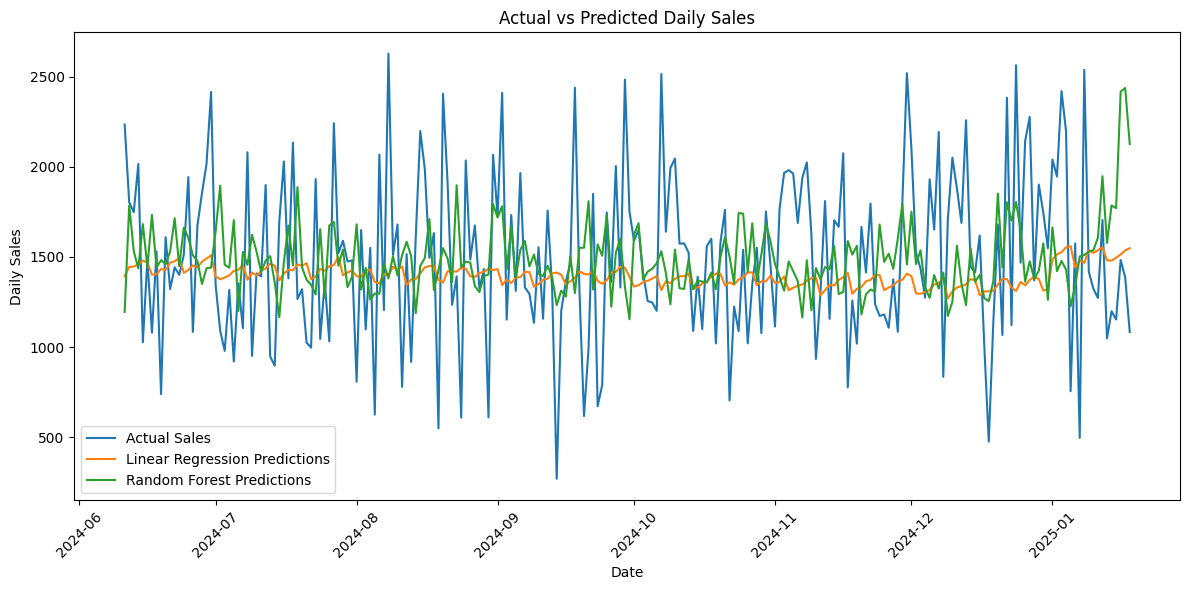

In [9]:



plt.figure(figsize=(12, 6))


plt.plot(
    daily_sales["Date"].iloc[split_index:],
    y_test.values,
    label="Actual Sales"
)


plt.plot(
    daily_sales["Date"].iloc[split_index:],
    lr_predictions,
    label="Linear Regression Predictions"
)


plt.plot(
    daily_sales["Date"].iloc[split_index:],
    rf_predictions,
    label="Random Forest Predictions"
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()


plt.show()


               Feature  Importance
4   Previous_Day_Sales       0.278
5  Previous_7_Days_Avg       0.274
2                  Day       0.180
1                Month       0.122
3            DayOfWeek       0.096
0                 Year       0.050


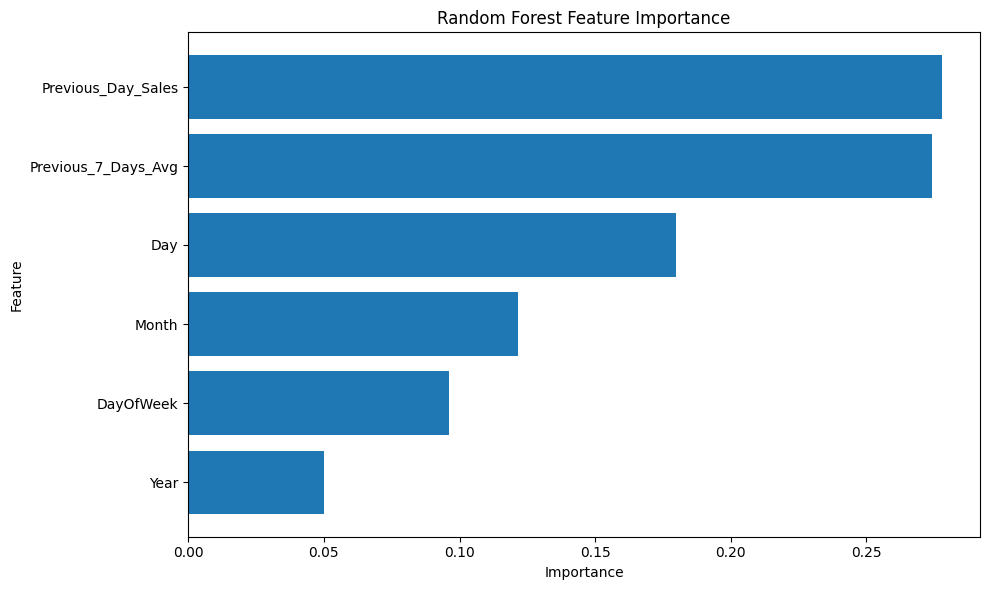

In [10]:


importance = rf_model.feature_importances_


feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})


feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)


print(feature_importance.round(3))


plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [11]:


from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor


param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}


tscv = TimeSeriesSplit(n_splits=3)


rf_tuning = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)


print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-grid_search.best_score_, 2))


best_rf_model = grid_search.best_estimator_


tuned_predictions = best_rf_model.predict(X_test)

print("\nTuning completed successfully!")


Best Parameters:
{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation MAE:
465.28

Tuning completed successfully!


In [12]:


tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)


final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [lr_mae, rf_mae, tuned_mae],
    "RMSE": [lr_rmse, rf_rmse, tuned_rmse],
    "R2 Score": [lr_r2, rf_r2, tuned_r2]
})

print("Final Model Comparison:")
print(final_comparison.round(2).to_string(index=False))


best_model_name = final_comparison.loc[
    final_comparison["MAE"].idxmin(), "Model"
]

print("\nModel with the lowest test MAE:", best_model_name)


Final Model Comparison:
              Model    MAE   RMSE  R2 Score
  Linear Regression 381.69 479.23     -0.08
      Random Forest 412.00 506.82     -0.21
Tuned Random Forest 387.24 478.56     -0.07

Model with the lowest test MAE: Linear Regression


# Sales Prediction Project Report

# 1. Objective
The objective of this project is to predict daily sales using historical retail sales data and machine learning models.

# 2. Dataset Overview
The dataset contains retail transactions from January 2022 to January 2025. The transactions were grouped by date to calculate daily sales. After creating prediction features and removing rows without sufficient historical data, 1,107 records were available.

# 3. Feature Engineering
The following features were created: Year, Month, Day, Day of Week, Previous Day Sales, and Previous 7 Days Average Sales. These features help the models identify date patterns and use previous sales information.

# 4. Models Used
Three models were evaluated:
- Linear Regression
- Random Forest Regression
- Tuned Random Forest Regression

The dataset was divided chronologically into 80% training data and 20% testing data.

# 5. Model Performance

Linear Regression achieved the lowest MAE of 381.69. The tuned Random Forest model achieved a slightly lower RMSE of 478.56. However, all three models had negative R² scores, which indicates that their predictions were not sufficiently accurate on the test data.

# 6. Feature Importance
The Random Forest model identified Previous Day Sales and Previous 7 Days Average Sales as the most important features. Day of the month and Month also contributed to predictions.

# 7. Conclusion
The project demonstrated how historical sales data can be prepared and used to train and evaluate machine learning models. Linear Regression performed best in terms of MAE, but the negative R² scores show that further improvement is needed. Future work could include better seasonal features, additional retail information, and alternative forecasting methods.